# The Chocolate Bar Problem: A Coding Challenge

There are m chocolate bars of varying (integer) lengths and n hungry children who want
differing amounts of chocolate (again integer amounts).  

The aim is to feed all of the children the correct amount whilst making the fewest cuts to the chocolate bars.

For example, suppose the chocolate bars have lengths {2,5,7} and four children
want {4,3,2,1}, then you can solve the problem using 2 cuts.

Write a program to distribute chocolate so that you make as few cuts as possible.  

We are more interested in solutions that get close to the minimum than that take an exponential amount of time.  

Feel free to use any programming language you feel comfortable with and please write your code so that we can understand what you are doing.

Good luck! (Omer: Thank you !)

Example given in the question (Omer: Note that I added a child that takes the remaining 2+5+7 - 4+3+2+1 chocolate pieces - see questions and assumptions below):

```python
chunkSizes = [2,5,7]
chunkIdx = [0,2,7,14]
requested = [4,3,2,1,4]
```

In [1]:
#@title Installing requiremnets { vertical-output: true }
# Python package requirements run this once at the beginning
%pip install -q qubo-solver
%pip install -q numpy
import numpy as np
import qubosolver                         # imports torch etc., which fiddle with the warning filters

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning, module="jupyter_client")
warnings.filterwarnings("ignore", message=".*utcnow.*")


# Check numoy and qubosolver are working:
try:
    __import__('qubosolver')
    print(f"qubosolver can be imported.")
except ModuleNotFoundError:
    print(f"qubosolver is NOT installed, we need this to continue.")


qubosolver can be imported.


## Some boundary questions and assumptions
1. I am assuming that there is enough chocolate to go around. (and not:  handle cases where there isn't enough, by, for example, trying to even the hunger between children or raise a ValueError)


2. The amount of chocolate needs to be exact, right ? meaning I can't give a child more than they want ?


3. I'm assuming if there is more chocolate than needed, the rest is kept aside (as if there is one more child who always asks for the amount that is the excess).


4. I'm assuming a child does not request 0 chocolate.

5. I'm assuming that putting together chocolate pieces is ok (it's still chocolate) and doesn't cost anything (no penalty).




## The way the rest of this solution is structured
1. First try to understand what a solution looks like (list, masks, matrix...) and frame it mathematically.

2. Then implement a function that calculates the number of cuts for a solution and validates a solution.

3. Implement a brute force solution, which will give *some* (not necessarily optimal) cutting solutions for problems within the boundaries above, and such that if we brute force through it will give *ALL* solutions although reallistically I disabled this option since even for small sizes this doesn't make sense.

4. Try look for a reduction to make the solution simpler.

5. Try to implement a heuristic that tries to give SOME solution in real time, better than the reference.

*I ended up using a QUBU formulation, seeded by the brute force solution*

5. I'm using python, with the help of Claude code to check the code matches my design instructions. There is a cell below that should install dependencies (numpy and qubo-solver from Pasqal).

6. Potentially: benchmark the reference solution against heuristics, measuring time and how far is the heuristic from the reference (so I'll need something to generate test cases maybe).

I stated where I used Claude code inline, but generally I use it to check my code, locate bugs from documentation and diagnosing crashes.

## First attempt at the problem

It smells like an NP problem, so the first thing I'll try to do is think what an optimal solution looks like, and hopefully get an idea for a heuristic.
The example given in the question could be written as three chocolate blocks A,B,C and a cut is a vertical line.

A solution with just two cuts:
AA B|BBBB CCC|CCCC

I then decided that using binary masks might allow me to argue about the problem in matrix form.
Assuming the bars are laid horizontally and consecutvely, similarly to the AABBBBBCCCCCCC above, I could look at binary masks:

Mask for child 1: 0,0,0,1,1,1,1,0,0,0,0,0,0,0

Mask for child 2: 0,0,0,0,0,0,0,1,1,1,0,0,0,0

Mask for child 3: 1,1,0,0,0,0,0,0,0,0,0,0,0,0

Mask for child 4: 0,0,1,0,0,0,0,0,0,0,0,0,0,0

Mask for child 5 (the one that takes the remaining chocolate): 0,0,0,0,0,0,0,0,0,0,1,1,1,1


We will use an auxilary array, chunkIdx such that chuckIdx[0] = 0, chunkIdx[i + 1] = chunkIdx[i] + chunkSizes[i].
This array serves as a map from consecutive indices back to the chocolate bars.
So in particular chunkIdx[-1] = sum(chunkSizes)


## What does a valid solution look like
1. Given an ordering of the chocolate integers (blocks), chunkSizes, the corresponding auxilary array chunkIdx, and a list of requested chocolate R, a valid solution is:

2. A set of masks (row vectors with 0 and 1 entries), one mask per child such that:

    2.1 A non zero in location k, for chunkIdx[j]<= k < chunkIdx[j+1] means that the corresponding piece from bar number j is assigned to that child.
    
    2.1 The masks have mutual empty intersection (meaning two masks cannot have a 1 in the same index).

    2.2 Their union covers the chocolate blocks (assuming the amount of chocolate splits exactly), meaning np.count_nonzero() == np.sum(chunkSizes)

    2.3 The sum of non zeros in each child-mask is the requested pieces of chocolate, i.e., np.count_nonzero(mask for child i) == R[i]

### How do we calculate the number of cuts from a solution in this form:
1. A cut, within a chocolate bar, is when there is a switch from one mask to another mask.

2. So the number of cuts will be the number of transitions.

### What does an optimal solution look like (necessary, but not sufficient condition):
1. A mask that is contiguous within a chocoalte bar will yield less cuts than a fragmented one (a mask which support on a chocolate bar is split by another mask m2). You can verify this by looking at the place where the mask is fragmented m1-m2-m1, and by swapping it to m2-m1-m1 you save a cut. So an optimal solution has no fragmented masks.

2. If the masks on a chocolate bar are not fragmented, then the number of cuts *per bar* is the same as the number of masks which are supported on that bar -1 (so if the bar is split between 2 children, there is 1 cut, if 3 children, there are 2 cuts)


If we stack all the masks vertically, we get a matrix A with 0 and 1 entries, such that:

1. A is of size (number of children) X cummulative number of chocolate pieces == len(R) X chunkIdx[-1] (so if the sizes are 2,5,7 there will be 2+5+7 columns).

2. The sum over row i equals how much child i asked for.

3. There is exactly one non zero in each column.

Note that this means that *any* permutation on the *columns*, preserves the above properties.

If we restrict A to columns chunkIdx[j] <= k < chunkIdx[j+1], then we get the restriction of the solution to the j'th chocolate bar, i.e.:

That means (potential reduction ?) that column permutations that respect the the bar indecies (meaning keep a column with index chunkIdx[l] <= k < chunkIdx[l+1] within that range), do not change the number of pieces a child claims from bar number l.

Finally, note that any solution can be represented in such form.


1. The support of the rows have mutual empty intersction.

2. The sum of non zeros in A[: , chunkIdx[j] : chunkIdx[j+1]] == chunkSizes[j] (the size of the j'th chocolate bar, every chocolate bar is fully claimed and cannot be doubly claimed - this is because any solution for the case where the sum of requested chocolate is strictly less than the total amount, can be padded with a bin-child that cliams what's left).

3. The rank of A reduced to columns chunkIdx[j] : chunkIdx[j+1] is the MINIMAL number of cuts on chunk j for this specific solution (and this number of cuts can be obtained by reordering the columns within this subset, which will correspond to making the selection of each child consecutive on that chocolate bar).


So to summarise we have a way to:

1. Slightly optimize a given solution to yield the minimal number of cuts on each chocolate bar using the same assignment (*NOT THE SAME AS HAVING A MINIMAL NUMBER OF CUTS GLOBALLY*) using permutations on columns that respect the array chunkIdx. We'll call such a solution "locally optimal". (this is the same as clustering masks together).
2. Check the minimal number of cuts of any solution in this form simply check:
```python
sum([rank(A[:,chunkIdx[l]:chunkIdx[l+1]]) for l in range(len(chunkSizes))])
```

4. So in particular, when we come to the point of guessing (randomizing) solutions, we don't need to randomize over the entire solution space (for example by trying all permutations of the rows), just assign weights, i.e.:

For a list of chocolate bars [b_1,b_2,...]

And for each child number i, how much chocolate is this child requesting *from each bar b_k*.

If we manage to guess a good solution, then by permuting the columns *within* each chocolate bar (to make the masks contiguous) will give a locally optimal solution.

### Counter example to think about:
We can't assume that an optimal solution *does not* have a masks that is fragmented accross many bars, for example:

4,4

3,3,1,1,

A solution with 2 cuts:

AAAA BBBB

0002 1113

Which is better than a "conseutive" placement:

0001 1123

which requires 3 cuts


### Reduction / easy win
If some child, say child number k, is requesting a number of pieces requested[k] which happens to be matching the size of some chocolate bar chunkSizes[l], assign that chocolate bar to that child.

This does not make optimal solutions worse:

If there is another solution where this bar is given to some other child(ren) then either:

1. It is given to a single child number $k' \neq k$ so swapping would not change the number of cuts.

2. The chocolate bar is split between several children. In which case, assigning them the pieces that child $k$ is currently claiming and cutting them (internally) like there present bar is cut will not add more cuts than the present state already has, whereas assigning their bar to child $k$ at worse doesn't add more cuts either (but potentially reduces the number of cuts).


I haven't implemented the above reduction in the code below, since I was aiming at writing code that solves the non-reduced problem.

### Checker function
So let's first code a function that accepts a solution (a stack of masks) and an array of chunk sizes, and calculates how many cuts an *EQUIVALENT*, locally optimal solution would have (meaning one where on each bar, each mask is contiguous == not fragmented):

In [2]:
#@title Counting the (locally optimal) number of cuts from a mask-style solution { vertical-output: true }
import numpy as np
chunkSizes = [2, 5, 7]
requested = [1,2,3,4,4] # Note that this is a full / balanced covering
exampleSolution = np.array([[0,0,1,0,0,0,0,0,0,0,0,0,0,0],[1,1,0,0,0,0,0,0,0,0,0,0,0,0],[0,0,0,0,0,0,0,1,1,1,0,0,0,0],[0,0,0,1,1,1,1,0,0,0,0,0,0,0],[0,0,0, 0,0,0, 0,0,0,0,1,1,1,1]])

def verifySolutionAndCountCutsFromMasks(A, chunkSizes, requested):
    """
    A - a solution matrix, i.e.:
    A is binary.
    Exactly one non zero in each column.
    Sum of non zeros is the same as A.shape[1]
    chunkSizes - a list of integers strictly bigger than 0 (assumed, no safety)

    Returns the number of cuts this solution would require, IF it would be brought to locally optimal form (not assumed !), meaning: the masks, when restricted to each bar, are contiguous within that bar.as_integer_ratio

    """
    import numpy as np
    from numpy.linalg import matrix_rank as mr


    if np.any(np.count_nonzero(A, axis=0) != 1):
        raise ValueError("A valid solution must have exactly one non zero in each column.")

    if np.count_nonzero(A) != A.shape[1]:
        raise ValueError("The total number of non zeros must equal the number of columns in A")

    if np.any(A != (A.astype(np.int32) % 2)):
        raise ValueError("A must be binary")

    for k in range(A.shape[0]):
        if np.sum(A[k,:]) != requested[k]:
            raise ValueError(f"Row k is a mask for child k, and has to sum up to be exactly requested[k] but {np.sum(A[k,:])} != {requested[k]}")

    # Create the indexing array
    chunkIdx = [sum(chunkSizes[:i]) for i in range(len(chunkSizes) + 1)]

    numberOfCuts = 0
    for i, j in zip(chunkIdx, chunkIdx[1:]):
        numberOfCuts = numberOfCuts + mr(A[:, i:j]) - 1
    return numberOfCuts

print(exampleSolution)

print(f"The minimal number of cuts for the example given in the excersize should be 2, and our solution checker gives: {verifySolutionAndCountCutsFromMasks(exampleSolution, chunkSizes=chunkSizes, requested=requested)}")

[[0 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 1 1 0 0 0 0]
 [0 0 0 1 1 1 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 1 1 1 1]]
The minimal number of cuts for the example given in the excersize should be 2, and our solution checker gives: 2


## Brute force solution
The formulation as a stack of masks makes it easy to implement a brute force solution, i.e., a solution that if we iterate through all its possibilities we'll get an optimal solution (since we'll have a list of all solutions).


In [3]:
def referenceSolution(chunkSizes, requested, numberOfPermutations = 10, seed = 0):
     """
     For two arrays of strictly positive integers (no safety on data type), with same sum, generate numberOfPermutations solutions (potentially equivalent).

     I deliberately disabled the ability to iterate through ALL permutations, you can bypass this by setting the number of permutations to the actual number of permutation for small cases.

     WARNING ! Obviously don't try all permutations for large values of sum(chunkSizes) (no safety, be reasonable)
     """
     # from itertools import permutations- disabled
     import copy

     if np.any(np.array(chunkSizes) <= 0) or np.any(np.array(requested) <= 0):
          raise ValueError("Only strictly positive integers are allowed for chuckSizes and requested.")
     if np.any(np.array(requested) < 0):
               raise ValueError("Only strictly positive integers are allowed for requested.")
     if np.sum(chunkSizes) != np.sum(requested):
          raise ValueError(f"The assumption is that the sum of requested == sum of chunkSizes, but you plugged in np.sum(requested) == {np.sum(requested)} and np.sum(chunkSizes)=={np.sum(chunkSizes)}")

     # Create a local instance of numpy random generator, to avoid setting the seed globally
     localRandom = np.random.RandomState(seed)

     # Create a valid solution, which is simply assigning child k requested[k] pieces in consecutive order based on the chunkSizes array
     numberOfPieces = np.sum(chunkSizes)
     numberOfChildren = len(requested)

     chunkIdx = [sum(chunkSizes[:i]) for i in range(len(chunkSizes) + 1)] #TODO: Omer: consider removing since I'm not using this in this version.

     masks = np.zeros((numberOfChildren, numberOfPieces), dtype = np.int32)
     lastAssignedIndex = 0
     for k in range(numberOfChildren):
          masks[k,lastAssignedIndex : lastAssignedIndex + requested[k]] = 1
          lastAssignedIndex += requested[k]

     allSolutions = []
     if numberOfPermutations > 0:
          for _ in range(numberOfPermutations):
               newSolution = copy.deepcopy(masks) # These two lines are the same as before there some code duplication code duplication code duplication here ....
               allSolutions.append(newSolution[:, localRandom.permutation(numberOfPieces)]) # These two lines are the same as before (did I say that ?)
     else: # Return just the (list of) baseline masks
          allSolutions.append(masks)
     # Sanity check: use the checker function to make sure we have valid solutions

     numberOfCuts = []
     for m in allSolutions:
          numberOfCuts.append(verifySolutionAndCountCutsFromMasks(m, chunkSizes=chunkSizes, requested=requested))

     return allSolutions, np.array(numberOfCuts)


# Sanity check - let's generate some solutions for some easy test cases:
chunkSizesExample1 = [2, 5, 7]
requestedExample1 = [1,2,3,4,4]

print(referenceSolution(chunkSizes=chunkSizesExample1, requested=requestedExample1))

([array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0],
       [1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1]], dtype=int32), array([[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
       [1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1],
       [0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0]], dtype=int32), array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
       [0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0],
       [0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1],
       [1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0]], dtype=int32), array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
       [0, 1, 0, 0, 0, 1, 0, 1, 0, 

## Test case generator
Ok now what I want to do is create a functions that generates valid test cases, meaning list pairs of chocolate bars and requested chocolate.
I might not use it, but it would be good to try validate any solution on it.

In [4]:
#@title A function to generate some random cases, to be used later for benchmarking { vertical-output: true }
def generateRandomTestCases(maxNumberOfChunks, maxChunkSize, maxNumberOfChildren):
    """
    maxNumberOfChunks >=2
    maxNumberOfChildren >=3
    maxChunkSize >=1
    Generate valid pairs of lists for chocolate bar sizes, and children requesting them.
    I didn't cover the entire space of cases, just wanted to generate a variaty.
    """
    import numpy as np

    numberOfChildren = np.random.randint(2,maxNumberOfChildren, dtype = np.int32)
    chunkSizes = [np.random.randint(1,maxChunkSize) for _ in range(maxNumberOfChunks)]

    requestedSizes = []
    chocolateRemaining = sum(chunkSizes)
    for c in range(numberOfChildren - 1):
        if chocolateRemaining <= 1:
            break
        newRequest = np.random.randint(1,chocolateRemaining)
        #print(newRequest)
        requestedSizes.append(newRequest)
        chocolateRemaining = chocolateRemaining - newRequest
    if chocolateRemaining > 0:
        requestedSizes.append(chocolateRemaining)

    return sorted(chunkSizes), sorted(requestedSizes)


## The problem is NP hard

At this point, I became confident enough that this problem is NP hard, and I asked Claude to confirm that it is (but not for a solution for it).

The way I formulated the problem as binary masks, is almost in QUBO form, which, now that I know the problem is NP hard makes sense to use as a reference solution.

***It's also really relevant to quantum computing as Pasqal for example already aim to solve QUBO problems, see https://pasqal-io.github.io/qubo-solver/latest/get_started/quickstart/***

In a QUBO setting, we encode the problem into binary variables, x, and a matrix of penalties, Q (real valued, upper triangular), such that an optimal solution is an assignment of x which *minimises*:

$$x^T Q x$$

Which for an upper triangular matrix, can be expanded to:

$$x^T Q x = \sum_{u \leq v} Q_{uv}\, x_u x_v$$

(the $u\leq v$ is because Q is upper triangular).

So a penalty is a positive contribution, and a reward is a negative contribution.

I'll be following this paper https://dl.acm.org/doi/epdf/10.1145/3638530.3664106 which is a really nice demonstration of encoding a problem into QUBO form.

Basically - you need to encode the problem into binary variables, encode "bad" or non valid assignments of the variables into penalties which are quadratic in the variables, and a QUBO solver will do the rest.

***Clarification the QUBO solver from Pasqal is really just a bunch of heuristics, which depend on the search type, number of seeds, QUBO parameters etc. ***

Fix an array of children requests
```python
requested[k]
```
= how many chunks does child k requests

And an array of chocolate bar sizes
```python
chunkSizes[i]
```
 = size of chocolate bar i

For each chocolate bar we fix an enumeration of its pieces

We will use binary variablel z[i,j,k] which will have the meaning: z[i,j,k] = 1 means that child k will recieve chunk number j of chocolate bar number i.

What does a valid (not necessarily optimal) solution look like:

1. Each child gets exactly what they asked for, not less or more:
$$\forall k (\sum _{i,j}z[i,j,k]) = request[k]$$
2. Each chocolate bar is distributed in full (recall that I'm assuming that the sum of requests equals the sum of chocolate bars).
$$\forall i (\sum_{j,k}z[i,j,k])=chunkSize[i] $$
3. A single chocolate piece cannot be given to more than one child
$$\forall i,j \forall k\neq k' z[i,j,k]\cdot z[i,j,k'] = 0$$

To say that child $k$ gets any piece of chocolate bar number $i$ is the same as the following formula, evaluating to true:

$$\bigvee_{j}z[i,j,k]$$

So we will also encode this into binary variables, i.e.:
$$ w[i,k] $$
Is the truth value of
$$\bigvee_{j}z[i,j,k]$$

Then the number of cuts on chocolate bar number $i$ is:
$$ \sum_{k}w[i,k] - 1 $$

And so, the total number of cuts is
$$ \sum_{i} (\sum_{k}w[i,k] - 1) $$

And we want minimise this last term, Which is equivalent to minimising
$$\sum_{i,k}(w[i,k]) $$

(we calculate the  constant, remove it for solving QUBO and bring it back when we want to read the answer).

but we also need to tie it back to the z[i,j,k] (we need to encode / inform that w[i,k] is a function of the z[i,j,k]s ), because at the moment,
It may be possible to assign z[i,j,k] = 1 and w[i,k] = 0
So we add a penalty:
$$ F_1 = \lambda \cdot z[i,j,k] \cdot(1-w[i,k]) $$

This will mean that whenever z[i,j,k] is 1 (child k is assigned piece j of bar i) and w[i,k] is 0 (signaling child k *does not* have any piece of bar i) we get a penalty (positive contribution).
We don't need to worry about symmetry (meaning w[i,k] = 1 implies z[i,j,k] = 1 for some j), since we are looking to minimize the w[i,k]s.

Now we will add penalties which are quadratic expressions in z and w (so that we can configure a matrix Q such that xQx^T will reflect the penalties).


1. Each child gets exactly what they asked for, not less or more:
$$\forall k (\sum_{i,j}z[i,j,k]) = requested[k]$$

For this we'll add for every $k$:
$$F_2 = \alpha (\sum_{i,j}z[i,j,k] - requested[k])^2$$

Where $\alpha$ is TBD

2. Each chocolate bar is distributed in full (recall that I'm assuming that the sum of requests equals the sum of chocolate bars)
$$\forall i (\sum_{j,k}z[i,j,k])=chunkSize[i] $$

For this we'll add for every $i$:
$$F_3 = \beta (\sum_{j,k}z[i,j,k] - chunkSize[i])^2$$

Where $\beta$ is TBD

3. A single chocolate piece cannot be given to more than one child
$$\forall i,j \forall k\neq k' z[i,j,k]\cdot z[i,j,k'] = 0$$

For this we will use the penalty term, for every $k \neq k'$:
$$F_4 = \gamma z[i,j,k]\cdot z[i,j,k']$$
Which is $\gamma$ both are $1$ (and $\gamma$ is TBD).

In order to place all these penalties into an upper triangular matrix Q, similarly to the Soduku paper, we now need a bijection between indices [i,j,k] and consecutive numbers. The actual map / bijection doesn't matter, but we need to fix one.

The following bijection will make it easy to read a solution from the z variables (basically each child, k,  is assigned a continuous set of variable with indices ranging from k_0 * sum(chunkSizes) to (k_0+1)*(sum(chunkSizes)) - 1 ):

$$ u(i_0,j_0,k_0) = \sum_{i<i_0}chunkSizes[i] + j_{0} + k_{0}\cdot(\sum_{i}chunkSizes[i])$$

So everywhere from now on when I write
$$(i,j,k) < (i1,j1,k1)$$
It is simply an abuse of notation to mean:
$$u(i,j,k) < u(i1,j1,k1)$$

We also need a continuous enumeration of the $w[i,k]$ that begins after all the $z[i,j,k]$, so I'll use:

$$v(i_{0},k_{0}) = len(requested) \cdot \sum_{i}chunkSizes[i] + k_{0}\cdot len(chunkSizes)+ i_{0}$$

Next we'll be using the following to remove constants (which QUBU can't handle) and stay with linear terms:

For a (non binary) sum of binary variable $S = s_1 + s_2 + ...$
$$(S - R)^2 = S^2 -2RS + R^2$$

The term $S^2$ can be written as:

$$(s_1 + s_2 + ...)^2 = s_1 ^2 + s_2^2 + ... + 2\cdot \sum_{u<u'}s_u\cdot s_{u'} $$
Since $s_i \in {0,1}$, this is equal:
$$s_1 + s_2 + ... + 2\cdot \sum_{u<u'}s_u\cdot s_{u'} $$
Which is
$$ S + 2\cdot \sum_{u<u'}s_u\cdot s_{u'}$$

So in total:
$$(S - R)^2 = $$
$$S^2 -2RS + R^2 = S + 2\cdot \sum_{i<j}s_i\cdot s_j - 2\cdot R \cdot S + R^2$$

The notation $i<j$ is useful to us in QUBO, since we will want Q to be upper triangular.


And using the above calculation for $S = \sum_{i,j}z[i,j,k]$ and $R = requested[k]$
And the above mapping $u$, which effectively flattens the array z we can rewrite:
$$\alpha (\sum_{i,j}z[u(i,j,k)] - requested[k])^2 = $$
$$\alpha (\sum_{i,j}z[u(i,j,k)] + 2\cdot \sum_{u(i_1,j_1,k)<u(i_2,j_2,k)}z[u(i_1,j_1,k)]\cdot z[u(i_2,j_2,k)] - 2\cdot requested[k] \cdot \sum_{i,j}z[u(i,j,k)] + requested[k]^2)$$

Which after removing the constant $ requested[k]^2$ leaves us with:
$$\alpha (\sum_{i,j}z[u(i,j,k)] + 2\cdot \sum_{u(i_1,j_1,k)<u(i_2,j_2,k)}z[u(i_1,j_1,k)]\cdot z[u(i_2,j_2,k)] - 2\cdot requested[k] \cdot \sum_{i,j}z[u(i,j,k)])$$

Similarly for
$$\beta (\sum_{j,k}z[u(i,j,k)] - chunkSize[i])^2$$
We write (at this point we can use Claude to help calculate and check for validity):
$$\beta (\sum_{j,k}z[u(i,j,k)] - chunkSize[i])^2 = $$
$$\beta(\sum_{j,k} z[u(i,j,k)] - chunkSize[i])^2 = \beta(1 - 2\cdot chunkSize[i])\sum_{j,k} z[u(i,j,k)] + 2 \cdot \beta \sum_{u(i,j,k) < u(i,j',k')} z[u(i,j,k)]\, z[u(i,j',k')] + \beta chunkSize[i]^2 $$

Which after removing the constant $\beta chunkSize[i]^2$ leaves us with:
$$\beta(\sum_{j,k} z[u(i,j,k)] - chunkSize[i])^2 = \beta(1 - 2\cdot chunkSize[i])\sum_{j,k} z[u(i,j,k)] + 2 \cdot \beta \sum_{u(i,j,k) < u(i,j',k')} z[u(i,j,k)]\, z[u(i,j',k')]$$


So now we "only" need to define $Q_{w_1,w_2}$ for every $u,u'$ in $0 .. max(Im(u))... max(Im(v))$.

This needs to reflect *exactly* the functions we wrote above, and since

$$x^T Q x = \sum_{w \leq w'} Q[w,w'] x_w \cdot x_w'$$

It means we have to collect the penalty terms above for every combination of $z[u]*z[u'] or z[u]*w[v] or w[v]*w[v']$

First, for the $w[i,k]$ variables we need:
$$Q[v(i,k), v(i,k)] = 1$$

Then on the diagonal in the range of the $z[i,j,k]$ variables (this says what every z[i,j,k] contributes from $F_1,F_2,F_3$):
$$Q[u(i,j,k),u(i,j,k)] = \lambda + \alpha(1-2\cdot requested[k]) + \beta\cdot (1-2\cdot chunkSizes[i])$$

Further for the entries in $Q$ that relate to $F_1$
$$Q[u(i,j,k),v(i,k)] = -\lambda$$
For $k<k'$, we have $u(i,j,k) < u(i,j,k')$ and so from $F_3$ and $F_4$:
$$Q[u(i,j,k),u(i,j,k')] = \gamma + 2\beta$$
From $F_3$, for $j\neq j', k < k'$:
$$Q[u(i,j,k),u(i,j',k')]= 2\beta$$
From $F_2, F_3$ for all $j<j'$
$$Q[u(i,j,k),u(i,j',k)] = 2\alpha + 2\beta$$
From $F_2$ for all $i<i'$:
$$Q[u(i,j,k),u(i',j',k)]	= 2\alpha$$

For all other entries, set them to 0.

(Now: Run through Claude to catch errors I made in the bijections, a sign error in expanding the sums, errors in parenthesese and in indexing (it's all indexing really) etc.)

Finally, we need to set values for
$$\lambda, \alpha, \beta, \gamma$$
And any assignment that satidfies:
$$\lambda, \alpha, \beta > 1 \qquad \gamma > 0 $$
Will work logically, but note that different assignments may change the ability of the solver to find optimal, and even feasible solutions.


Once QUBU gives us an answer, meaning a assignment of the variables z[i,j,k] and w[i,k], we can retrace the actuall cut, ***if we make sure to add the constants we removed*** which sum to:

$$C = \alpha\sum_k requested[k]^2 + \beta\sum_i chunkSizes[i]^2 - len(chunkSizes)$$
And if we only want the *number* of cuts for an optimal solution it would be:
$$number of cuts = x^T Q x + C$$



In [5]:
#@title Formulating the problem as a QUBO { vertical-output: true }
"""
Implementation of the above formulation of finding a distribution of the chocolate bars which sizes are given in
chunkSizes 1D array of integers >0
To children requests given as a 1D array of integers > 0
requested

Plan:
1. Use the above arrays for two encoding functions u and v
2. Assemble the matrix Q
3. Hand over to a QUBU solver (will be done in a separet cell)
4. A decoding function, so that any solution to x^T Q x can be represented as a stack of binary masks, one mask per child.

"""
import numpy as np
from itertools import combinations

def u(chunkSizes, i, j, k):
    #$$ u(i_0,j_0,k_0) = \sum_{i<i_0}chunkSizes[i] + j_{0} + k_{0}\cdot(\sum_{i}chunkSizes[i])$$
    # IMPORTANT: there are many ways to encode, but the way we encode below makes it slightly easier to recover per child mask from the solution provided by the solver.
    return int(np.sum(chunkSizes[:i]) + j + k * np.sum(chunkSizes)) # Omer: I may need to use np.int64 for larger problems

# We'll also hold an inverse table for u (could be calculated in closed form, but we only need to generate this once)
def generateInverseTableU(chunkSizes, requested):
    inverseTable = {}
    for i in range(len(chunkSizes)):
        for j in range(chunkSizes[i]):
            for k in range(len(requested)):
                u0 = u(chunkSizes = chunkSizes, i = i, j = j, k = k)
                inverseTable[u0] = (i,j,k)
    return inverseTable

# Now for the v bijections:
def v(chunkSizes, requested, i,k):
    #$$v(i_{0},k_{0}) = len(requested) \cdot \sum_{i}chunkSizes[i] + k_{0}\cdot len(chunkSizes)+ i_{0}$$
    return int(len(requested)*np.sum(chunkSizes) + k * len(chunkSizes) + i) # May need to use np.int64 for larger problems

def generateInverseTableV(chunkSizes, requested):
    inverseTable = {}
    for i in range(len(chunkSizes)): # so i is in the range of number of bars
        for k in range(len(requested)): # and k is the child number
            v0 = v(chunkSizes=chunkSizes, requested=requested, i = i,k = k)
            inverseTable[v0] = (i,k)
    return inverseTable


# Now we move to build Q:

def generateQMatrix(requested, chunkSizes, lamda = 2, alpha = 2, beta = 2, gamma = 1):
    # Q is of dimension nXn where n is basically the range 0...,max(Im(u)),...max(Im(v))
    n = (len(requested) * len(chunkSizes) + np.sum(chunkSizes)*len(requested))
    Q = np.zeros((n,n)) # Unclear if changing datatype will really save anything when handing to a solver

    def _v(i,k):
        return v(requested=requested, chunkSizes=chunkSizes, i=i,k=k )
    def _u(i,j,k):
        return u(chunkSizes=chunkSizes, i=i,j=j,k=k)
    # objective: minimise sum_{i,k} w[i,k]      ->  +1 on each w diagonal
    for i in range(len(chunkSizes)):
        for k in range(len(requested)):
            Q[_v(i, k), _v(i, k)] += 1.0

    # F1 = lam * z[i,j,k] * (1 - w[i,k])  =  lamda*z  -  lamda*z*w
    for k in range(len(requested)):
        for i in range(len(chunkSizes)):
            for j in range(chunkSizes[i]):
                Q[_u(i, j, k), _u(i, j, k)] += lamda
                Q[_u(i, j, k), _v(i, k)] += -lamda     # the -lamda*z*w  term

    # F2 = alpha * (sum_{i,j} z[i,j,k] - requested[k])^2
    #    = alpha*(1-2R)*sum z  +  2*alpha*sum_{pairs} z*z
    for k in range(len(requested)):
        idx = [_u(i, j, k) for i in range(len(chunkSizes)) for j in range(chunkSizes[i])]
        for a in idx:
            Q[a,a] += alpha * (1 - 2 * requested[k])
        for a, b in combinations(idx, 2):
            Q[a,b] += 2 * alpha

    # F3 = beta * (sum_{j,k} z[i,j,k] - chunkSizes[i])^2   (same expansion)
    for i in range(len(chunkSizes)):
        idx = [_u(i, j, k) for k in range(len(requested)) for j in range(chunkSizes[i])] # Notice that there is importance to k first j second, in order to make sure we get a Q which is upper triangular
        for a in idx:
            Q[a,a] +=  beta * (1 - 2 * chunkSizes[i])
        for a, b in combinations(idx, 2):
            Q[a,b] += 2 * beta

    # F4 = gamma * z[i,j,k] * z[i,j,k']   for every pair k < k'
    for i in range(len(chunkSizes)):
        for j in range(chunkSizes[i]):
            for k, kp in combinations(range(len(requested)), 2):
                Q[_u(i,j,k), _u(i,j,kp)] += gamma

    # constant that is removed from the penalty functions, we want this for when the solver provides an answer (number):
    C = alpha * sum(r * r for r in requested) + beta * sum(b * b for b in chunkSizes) - len(chunkSizes)
    # So number of cuts = x^T Q x + C
    return Q, C

# Finally, we want a decoding function, i.e., a function that takes any solution (not necessarily optimal) to x^T Q x produced by a solver, and writes it as binary masks for us to apply the checker function above
def decodeToMasks(x, requested, chunkSizes):
    """
    x is flat bit vector from the a QUBU solver for x^T Q x
    Returns
      A: (len(requested), sum(chunkSizes)) binary matrix, A[k, p] = 1 if child k claims piece number p (recall that p runs from 0 to sum(chunkSizes))
      W: (len(requested), len(chunkSizes)) binary matrix, W[k, i] = solver's w[i,k]
    """
    nk, ni, P = len(requested), len(chunkSizes), int(np.sum(chunkSizes))
    x = np.asarray(x, dtype=int)
    A = x[:len(requested) * int(np.sum(chunkSizes))].reshape(len(requested), int(np.sum(chunkSizes)))       # This is correct, because of the way we encoded u(i,j,k) = np.sum(chunkSizes[:i]) + j + k * np.sum(chunkSizes)
    W = x[len(requested) * int(np.sum(chunkSizes)):].reshape(len(requested), len(chunkSizes))      # this is because v(i,k)  = int(len(requested)*np.sum(chunkSizes) + k * len(chunkSizes) + i)
    return A, W

# We also have a function to encode a solution in masks form to a QUBU solution, we will use this later
def encodeMasksToX(A, chunkSizes):
    """
    Inverse of decodeToMasks.
    A: (len(requested), sum(chunkSizes)) binary mask matrix, A[k, p] = 1 if child k holds global piece p.
    Returns x: flat bit vector consistent with u(i,j,k) and v(i,k),
    with w[i,k] set to OR_j z[i,j,k].
    """

    # w[i,k] = 1 iff child k has any piece in bar i
    chunkIdx = [sum(chunkSizes[:i]) for i in range(len(chunkSizes) + 1)]
    W = np.zeros((A.shape[0], len(chunkSizes)), dtype=int)                     # W[k, i], matching v(i,k) = nk*P + k*ni + i
    for i in range(len(chunkSizes)):
        W[:, i] = A[:, chunkIdx[i]:chunkIdx[i + 1]].any(axis=1)


    return np.concatenate([A.ravel(), W.ravel()])

### Sanity checks for our indexing
Let's do some sanity checks to make sure we're getting upper triangular Q and we didn't get the indexing wrong:

In [6]:
#@title Sanity checks number of cuts from a mask-style solution { vertical-output: true }
# Sanity checks:

requested, chunkSizes = [2, 1], [2, 1]
Q, C = generateQMatrix(requested, chunkSizes)

# Q is upper triangular
for i in range(Q.shape[0]):
    for j in range(Q.shape[0]):
        if i>j:
            assert Q[i,j] == 0
print(f"Assertions passed for checking Q is upper triangular for example 1.")

chunkSizes = [1,1,1]
requested = [1,2,3]
Q, C = generateQMatrix(requested, chunkSizes)

# Q is upper triangular
for i in range(Q.shape[0]):
    for j in range(Q.shape[0]):
        if i>j:
            assert Q[i,j] == 0
print(f"Assertions passed for checking Q is upper triangular for example 2.")

# Omer: In case you want to eyeball Q disable the following line:
#Q, constant = generateQMatrix(chunkSizes=chunkSizes, requested=requested)
#print(Q)

Assertions passed for checking Q is upper triangular for example 1.
Assertions passed for checking Q is upper triangular for example 2.


### Now let's take a very small case and see how Pasqal's emulator solves it:
For the parameters
```python
requested = [2, 1]
chunkSizes = [2, 1]
```
We are expecting 0 cuts - and using the below settings it solved it correctly (note that if we were to use the reduction, then this test case would have been made trivial).

For the parameters (the example given in the excersize):
```python
requested = [1,2,3,4,4] # Note that this is a full / balanced covering
chunkSizes = [2, 5, 7]
```

***We are expecting 2 cuts, but when I ran it it struggled to find feasible solutions, and currently only finds a solution with 3 (!) cuts***

Note that this is Pasqal's QUBU emulator, so the perfomance (time to run) will depend on the machine running this notebook, AND:

Finding an optimal solution (and in fact a feasible solution) might require many seed (starts in their lingo), and also different search heuristics

In [7]:
#@title Check whether or not the QUBO solver finds an optimal solution, check if it finds any feasible solutions { vertical-output: true }
from qubosolver import Instance, Solver, matrix, analysis, solving, bitstrings, torch_rng

requested, chunkSizes = [2, 1], [2, 1]
Q, C = generateQMatrix(requested=requested, chunkSizes=chunkSizes)
print(f"Our formulation of the problem removed the constant C = {C}. So any solution with costs == {-C} is an optimal solution")
    # the pasqal qubo-solver asks a symmetric matrix, as in the soduku paper, we use:
S = matrix.tensor(0.5 * (Q + Q.T))
instance = Instance(S)
# Seeds for Pasqal's solver
starts = bitstrings.rand(2000, instance.size, rng=torch_rng(0))
#refined = solving.iterative_bitflip_local_search.solve(instance, starts=starts)
refined = solving.simulated_annealing.solve(instance, starts=starts)
df = analysis.to_dataframe([refined])
print("Here is what the output of the QUBU solver looks like:")
print(df)
bestSolution = df.loc[df["costs"].idxmin()]                 # the row with the lowest x^T Q x
x = np.array([int(b) for b in bestSolution["bitstrings"]])
print(f"An optimal solution is found in location {df["costs"].idxmin()}, which details are:")
print(bestSolution)
print(f"The x assignment that realizes this solution is: {bestSolution['bitstrings']}")
binaryVector = np.array([int(i) for i in bestSolution['bitstrings']])
print(binaryVector)
print(f"And  when we translate (decode) it back to one mask per child we get:")
A,W = decodeToMasks(x = binaryVector, requested=requested, chunkSizes=chunkSizes)
print("Which gives us the masks:")
print(A)
print(f"Now let's run it through the checker function, verifySolutionAndCountCutsFromMasks, if no errors are raised, and the answer is 0 it passes the test case:")

try:
  numberOfCutsForTestCase = verifySolutionAndCountCutsFromMasks(A, chunkSizes=chunkSizes, requested=requested)
  print(f"The solution is valid, and makes {numberOfCutsForTestCase} cuts.")
except:
  print(f"Solution is not valid, does not pass the checker function.")


requested = [1,2,3,4,4] # Note that this is a full / balanced covering
chunkSizes = [2, 5, 7]
print(f"Now repeat this excersize for: requested = {requested}, chunkSizes = {chunkSizes}")

Q, C = generateQMatrix(requested=requested, chunkSizes=chunkSizes)
S = matrix.tensor(0.5 * (Q + Q.T))
instance = Instance(S)

######## AWESOME FINDING !!! #################
# Seeds for Pasqal's solver !!!!!!!!!!!!!!!!!! THE SOLVER DOES NOT FIND ANY FEASIBLE SOLUTION IF I ALLOW ONLY 20 STARTING POINTS ! AND IT DOES NOT FIND AN OPTIMAL (2 CUTS) SOLUTION IF I ALLOW ONLY 200 STARTING POINTS !!!
starts = bitstrings.rand(2000, instance.size, rng=torch_rng(0))
refined = solving.simulated_annealing.solve(instance, starts=starts)
df = analysis.to_dataframe([refined])
bestSolution = df.loc[df["costs"].idxmin()]                 # the row with the lowest x^T Q x
x = np.array([int(b) for b in bestSolution["bitstrings"]])
binaryVector = np.array([int(i) for i in bestSolution['bitstrings']])
A,W = decodeToMasks(x = binaryVector, requested=requested, chunkSizes=chunkSizes)
print("We get the masks:")
print(A)
print(f"Now let's run it through the checker function, countCutsFromMasks:")

try:
  numberOfCutsForTestCase = verifySolutionAndCountCutsFromMasks(A, chunkSizes=chunkSizes, requested=requested)
  print(f"The solution is valid, and makes {numberOfCutsForTestCase} cuts.")
except:
  print(f"Solution is NOT VALID !!! does not pass the checker function.")

#print(f"Number of cuts for the best QUBO solution: {verifySolutionAndCountCutsFromMasks(A, chunkSizes=chunkSizes, requested=requested)}")

Our formulation of the problem removed the constant C = 18. So any solution with costs == -18 is an optimal solution
Here is what the output of the QUBU solver looks like:
   labels  bitstrings  costs  counts   probs
0       0  1100011001  -18.0    1127  0.5635
1       0  0111001110  -17.0     335  0.1675
2       0  1010101110  -17.0     363  0.1815
3       0  1100011000  -17.0      52  0.0260
4       0  1100011011  -17.0      43  0.0215
5       0  1100011101  -17.0      49  0.0245
6       0  0110101110  -16.0       5  0.0025
7       0  0111000110  -16.0       2  0.0010
8       0  0111001100  -16.0       2  0.0010
9       0  0111001111  -16.0       1  0.0005
10      0  1010100110  -16.0       5  0.0025
11      0  1010101010  -16.0       5  0.0025
12      0  1011001110  -16.0      10  0.0050
13      0  1100011111  -16.0       1  0.0005
An optimal solution is found in location 0, which details are:
labels                 0
bitstrings    1100011001
costs              -18.0
counts         

### Putting it all together:
The small experiment above showed that Pasqal's solver does not find a feasible solution if I only allow 20 random starting points (which are not necesserily valid solutions, they are just random assignments), and:

It does not find an optimal solution (2 cuts) with just 200 starting points, using Pasqal's generator:
```python
starts = bitstrings.rand(2000, instance.size, rng=torch_rng(0))
```

This made me realise that there is sense in feeding QUBU ***some*** feasible solution, which (when the number of pieces == total requested, which is the assumption I made) we can always find (just by assigning each child SOME requested[0] pieces), i.e.: using the reference solution.

So now let's:
1. Generate a few cases using our test case generator, and try to solve them using three methods:
2. Using just the reference solution - basically random but guaranteed (!) to be *valid*.
3. Using a QUBU matrix, and hand over to Pasqal's solver using 1, 10, 100, 1000 starting points.
4. Using the brute force / solution generator function to generate 1, 10, 100, 1000 possible solutions as a starting point.
5. Plot time, fraction of the solutions that were valid, and distribution of cuts for each solution.

I'm attaching below the result I got from running with:
```python
numberOfCasesToSolve = 20
maxNumberOfChunks = 6
maxNumberOfChildren = 6
maxChunkSize = 6
```

It takes approximately:
1 minute to run with 3 cases to solve using 4,4,6

2 minutes to run with 10 cases to solve using 4,4,6

6 minutes to run with 20 cases to solve using 6,6,6


### Some conclusions:
1. Obviously runtime of the brute force (reference) solution is lower.

2. As expected, when increasing the number of attempts, the brute force solution manages to find some minimal solutions (blue triangles at the bottom right).

3. When running the solver using random starting points, less than 50% of the solutions are valid.

3. When the solver is handed starting points generated by the reference solution, the validity of solutions rises to ~80%

4. What is unclear, is whether the solver is improving the starting points handed to it by the reference masks. If we look at the rightmost panel and the rightmost number of starts (check the figure I attached for 20 cases, not the hardcoded 3 cases I left for this notebook to finish faster), blue traingles (reference masks) align with green squares (solver running from these masks) *especially in 11 and 12 cuts*. However, if allowed to start from random starts (orange disks), we see that the solver did not hit 11 and 12 cuts


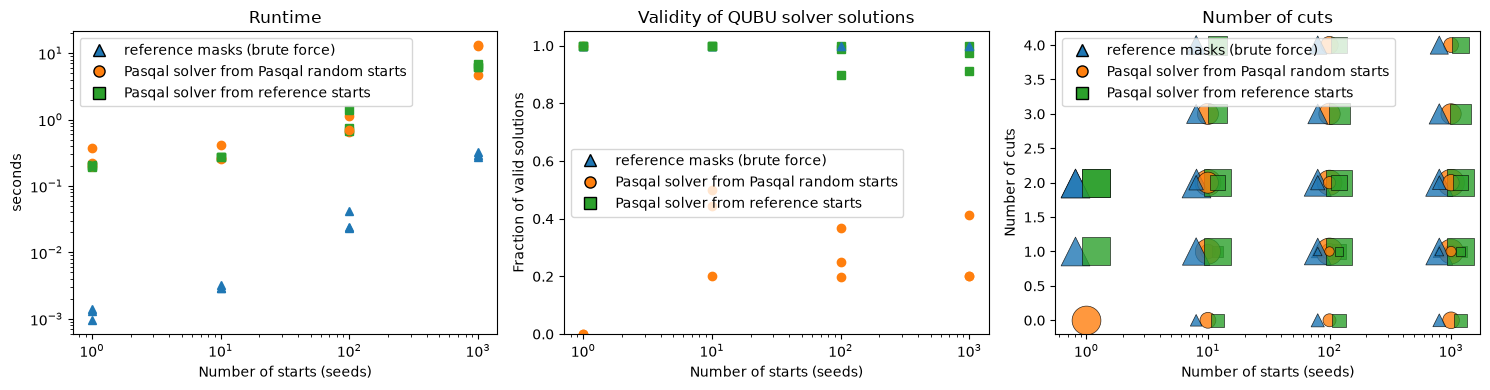

Plotting took 64.30272353600049 seconds


In [8]:
import time, torch
import pandas as pd
import matplotlib.pyplot as plt
from qubosolver import Instance, matrix, analysis, solving, bitstrings, torch_rng
from matplotlib.lines import Line2D

QUBU_STARTS_DATA_TYPE = bitstrings.rand(1, 1, rng=torch_rng(0)).dtype
# parameters
numberOfCasesToSolve = 3
maxNumberOfChunks = 6
maxNumberOfChildren = 6
maxChunkSize = 6

def analyseSolverOutput(chunkSizes, requested, refinedSolution):
  """
  Iterate over the solver output (list of solutions it found).
  For every output:
  1. Convert to bitstring.
  2. Encode to masks for.
  3. Use our checker to check validity of solution (row), and count cuts.

  Returns:
  numberOfValidSolutions, failed, list of cuts observed
  """
  failed = 0
  numberOfValidSolutions = 0
  cuts = []
  for _, r in analysis.to_dataframe([refinedSolution]).iterrows():
    x = np.array([int(b) for b in r["bitstrings"]])
    A, W = decodeToMasks(x, requested, chunkSizes)
    try:
        solutionCuts = verifySolutionAndCountCutsFromMasks(A, chunkSizes=chunkSizes, requested=requested)
        numberOfValidSolutions +=1
    except ValueError:
        solutionCuts = np.nan
        failed += 1
    cuts.append(solutionCuts)


  return numberOfValidSolutions, failed, cuts



fig, ax = plt.subplots(1, 3, figsize=(15, 4))



legendHandles = [
    Line2D([], [], linestyle="", marker="^", color="C0", markeredgecolor="k", markersize=8, label="reference masks (brute force)"),
    Line2D([], [], linestyle="", marker="o", color="C1", markeredgecolor="k", markersize=8, label="Pasqal solver from Pasqal random starts"),
    Line2D([], [], linestyle="", marker="s", color="C2", markeredgecolor="k", markersize=8, label="Pasqal solver from reference starts"),
]

plottingTime0 = time.perf_counter()
for i in range(numberOfCasesToSolve):

  # Generate some test case, modest parameters
  chunkSizes, requestedSizes = generateRandomTestCases(maxNumberOfChunks, maxChunkSize, maxNumberOfChildren)
  for startMethod in ["Pasqal", "reference"]:
    # Generate some test case, modest parameters
    Q, C = generateQMatrix(requested=requestedSizes, chunkSizes=chunkSizes)
    # the pasqal qubo-solver asks a symmetric matrix, as in the soduku paper, we use:
    S = matrix.tensor(0.5 * (Q + Q.T))
    instance = Instance(S)

    for numberOfStarts in [1, 10, 100, 1000]:
      if startMethod == "Pasqal":
        starts = bitstrings.rand(numberOfStarts, instance.size, rng=torch_rng(i))
      #elif startMethod == "reference":
      else:
        t0 = time.perf_counter()
        refMasks, refCuts  = referenceSolution(chunkSizes=chunkSizes, requested=requestedSizes,
                                          numberOfPermutations=numberOfStarts, seed= i)
        totalTime = time.perf_counter() - t0
        # We get the brute force  / reference masks for free so let's plot them



        sctterCuts = np.array(refCuts, dtype=float)
        sctterCuts = sctterCuts[~np.isnan(sctterCuts)]  # Remove nans

        vals, counts = np.unique(sctterCuts, return_counts=True)
        ax[2].scatter(np.full(len(vals), numberOfStarts * 0.8), vals,
                             s=30 + 400 * counts / counts.sum(), color="C0", alpha=0.8,
                          edgecolor="k", linewidth=0.5, marker = "^")

        ax[0].plot(numberOfStarts, totalTime, "^", color = "C0")
        ax[1].plot(numberOfStarts, 1.0, "^", color = "C0")


        starts = np.stack([encodeMasksToX(A, chunkSizes) for A in refMasks])
        starts = torch.as_tensor(starts).to(QUBU_STARTS_DATA_TYPE)


      # First try to solve using the random starts:
      t0 = time.perf_counter()
      refined = solving.simulated_annealing.solve(instance, starts=starts)
      totalTime = time.perf_counter() - t0
      numberOfValidSolutions, failed, cuts = analyseSolverOutput(requested=requestedSizes, chunkSizes=chunkSizes, refinedSolution=refined)
      if startMethod == "Pasqal":
        methodColor = "C1"
        methodMarker = "o"
        methodOffset = 1.0
      else:
        methodColor = "C2"
        methodMarker = "s"
        methodOffset = 1.2

      ax[0].plot(numberOfStarts, totalTime, marker = methodMarker, color = methodColor)
      ax[1].plot(numberOfStarts, numberOfValidSolutions / (numberOfValidSolutions + failed), marker = methodMarker, color = methodColor)
      sctterCuts = np.array(cuts, dtype=float)
      sctterCuts = sctterCuts[~np.isnan(sctterCuts)]  # Remove nans

      vals, counts = np.unique(sctterCuts, return_counts=True)
      if len(sctterCuts) > 0:
        ax[2].scatter(np.full(len(vals), numberOfStarts * methodOffset), vals,
                              s=30 + 400 * counts / counts.sum(), color=methodColor, alpha=0.8,
                            edgecolor="k", linewidth=0.5, marker = methodMarker)


ax[0].set(xscale="log", yscale="log", xlabel="Number of starts (seeds)", ylabel="seconds", title="Runtime")
ax[1].set(xscale="log", xlabel="Number of starts (seeds)", ylabel="Fraction of valid solutions", ylim=(0, 1.05), title="Validity of QUBU solver solutions")
ax[2].set(xscale="log", xlabel="Number of starts (seeds)", ylabel="Number of cuts", title="Number of cuts")
ax[0].legend(handles=legendHandles)
ax[1].legend(handles=legendHandles)
ax[2].legend(handles=legendHandles)
plt.tight_layout()
plt.show()
plottingTimeTotal = time.perf_counter() - plottingTime0
print(f"Plotting took {plottingTimeTotal} seconds")

## Comparison between brute force, Pasqal QUBU solver from random, and Pasqal QUBU solver from reference masks (brute force)

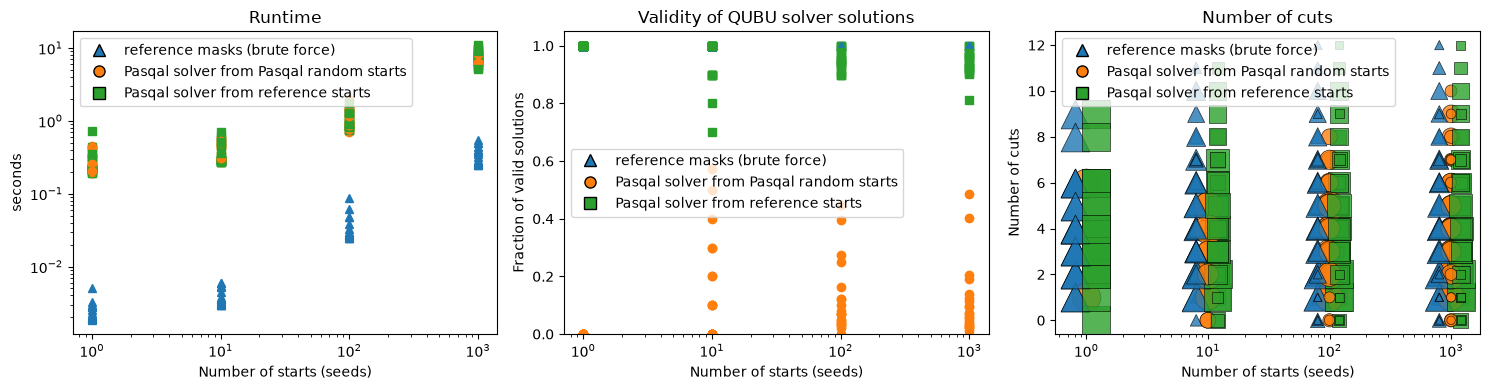